## 1D Diffusion

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Set the font family and size to use for Matplotlib figures.
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 10

In [4]:
# Define the grid and diffusion coefficient
nx = 41
L  = 2.0
dx = L / (nx - 1)
nu = 0.3
x  = np.linspace(0.0, L, num=nx)

# Choose a time step that reaches the requested final time
t_final = 0.04
r_target = 0.2
dt_target = r_target * dx**2 / nu

num_steps = int(np.ceil(t_final / dt_target))
dt = t_final / num_steps
r = nu * dt / dx**2

# Set the initial profile, including the fixed endpoint values
u0 = np.ones(nx)
mask = (x >= 0.5) & (x <= 1.0)
u0[mask] = 2.0

print(f'dx = {dx:.4f}, dt = {dt:.6f}, r = {r:.3f}')
print(f'{num_steps} steps to t = {num_steps * dt:.4f}')

dx = 0.0500, dt = 0.001667, r = 0.200
24 steps to t = 0.0400


In [5]:
def advance_diffusion(u0, nu, dx, dt, num_steps):
    '''Advance 1D diffusion with FTCS, holding both endpoints fixed.'''
    r = nu * dt / dx**2
    u = u0.copy()
    for n in range(num_steps):
        u[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
    return u


u = advance_diffusion(u0, nu, dx, dt, num_steps)

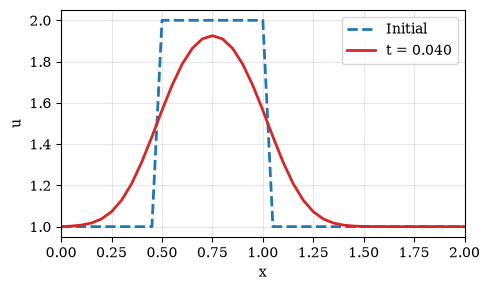

In [6]:
fig, ax = plt.subplots(figsize=(5.0, 3.0))
ax.plot(x, u0, label='Initial', linestyle='--', linewidth=2)
ax.plot(x, u, color='tab:red', label=f't = {t_final:.3f}', linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('u')
ax.set_xlim(0.0, L)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout();

In [9]:
# Check the initial profile
print("Initial endpoints:", u0[0], u0[-1])
print("Initial min/max:", u0.min(), u0.max())

# Check whether u0 was modified
print("After advance, u0 endpoints:", u0[0], u0[-1])
print("After advance, u0 min/max:", u0.min(), u0.max())

Initial endpoints: 1.0 1.0
Initial min/max: 1.0 2.0
After advance, u0 endpoints: 1.0 1.0
After advance, u0 min/max: 1.0 2.0


In [10]:
# Reuse the grid, nu, and r_target from the square-pulse calculation
A = 1.0
k = np.pi / L

t_final = 1.0
dt_target = r_target * dx**2 / nu
num_steps = int(np.ceil(t_final / dt_target))
dt = t_final / num_steps
r = nu * dt / dx**2

sine_profile = np.sin(k * x)
u0 = 1.0 + A * sine_profile

print(f'dx = {dx:.4f}, dt = {dt:.8f}, r = {r:.4f}')
print(f'{num_steps} steps to t = {num_steps * dt:.4f}')

dx = 0.0500, dt = 0.00166667, r = 0.2000
600 steps to t = 1.0000


In [11]:
u = advance_diffusion(u0, nu, dx, dt, num_steps)

midpoint = nx // 2
amplitude = u[midpoint] - 1.0

In [12]:
exact_rate = nu * k**2
amplitude_exact = A * np.exp(-exact_rate * t_final)
u_exact = 1.0 + amplitude_exact * sine_profile

Calculate how fast the wave's amplitude decays over time in your simulation and print out a clean comparison table pitting the Exact analytical solution against your Computed FTCS numerical results.

In [14]:
measured_rate = -np.log(amplitude / A) / t_final

print(f"{'Reference':<22} {'Final amplitude':>18} {'Decay rate':>16}")
for name, final_amplitude, rate in (
    ('Exact PDE', amplitude_exact, exact_rate),
    ('Computed FTCS', amplitude, measured_rate),
):
    print(f'{name:<22} {final_amplitude:18.10f} {rate:16.10f}')

Reference                 Final amplitude       Decay rate
Exact PDE                    0.4770088046     0.7402203301
Computed FTCS                0.4769725126     0.7402964153


FTCS ends with a slightly smaller amplitude than the exact solution, and its measured decay rate is slightly larger than 
$νk^2$. On this grid with this time step, the numerical solution decays slightly too quickly

**Measure the error**

In [15]:
error = np.max(np.abs(u - u_exact))
print(f'Maximum error against exact solution: {error:.3e}')

Maximum error against exact solution: 3.629e-05


**combined refinement study**

In [16]:
# Reuse L, nu, A, k, t_final, r_target, and exact_rate from the sine-profile setup
nx_values = [41, 81, 161]
refinement_results = []  # one dictionary of settings and measurements per grid

for nx in nx_values:
    dx = L / (nx - 1)
    x = np.linspace(0.0, L, num=nx)
    dt_target = r_target * dx**2 / nu
    num_steps = int(np.ceil(t_final / dt_target))
    dt = t_final / num_steps

    sine_profile = np.sin(k * x)
    u0 = 1.0 + A * sine_profile
    u = advance_diffusion(u0, nu, dx, dt, num_steps)

    u_exact = 1.0 + A * np.exp(-exact_rate * t_final) * sine_profile
    error = np.max(np.abs(u - u_exact))
    work = (nx - 2) * num_steps
    refinement_results.append({
        'nx': nx, 'num_steps': num_steps, 'error': error, 'work': work,
    })

In [17]:
print(f"{'nx':>5} {'steps':>7} {'max error':>12} {'order':>7} "
      f"{'updates':>10} {'work ratio':>11}")
previous = None
for result in refinement_results:
    if previous is None:
        order_text = '-'
        ratio_text = '-'
    else:
        order = np.log(previous['error'] / result['error']) / np.log(2)
        work_ratio = result['work'] / previous['work']
        order_text = f'{order:.3f}'
        ratio_text = f'{work_ratio:.2f}'
    print(f"{result['nx']:5d} {result['num_steps']:7d} "
          f"{result['error']:12.4e} {order_text:>7} "
          f"{result['work']:10d} {ratio_text:>11}")
    previous = result

   nx   steps    max error   order    updates  work ratio
   41     600   3.6292e-05       -      23400           -
   81    2400   9.0746e-06   2.000     189600        8.10
  161    9600   2.2688e-06   2.000    1526400        8.05


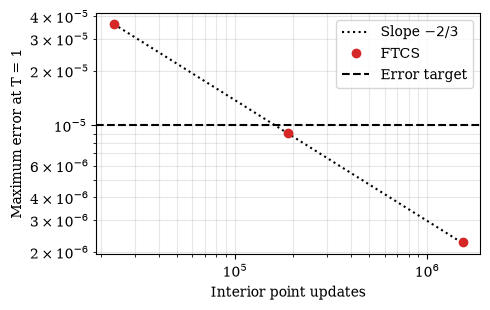

In [18]:
errors = np.array([result['error'] for result in refinement_results])
work_counts = np.array([result['work'] for result in refinement_results])
work_guide = errors[0] * (work_counts / work_counts[0])**(-2 / 3)
error_target = 1e-5

fig, ax = plt.subplots(figsize=(5.0, 3.2))
ax.loglog(work_counts, work_guide, color='black', linestyle=':',
          label='Slope $-2/3$')
ax.loglog(work_counts, errors, 'o', color='tab:red', label='FTCS')
ax.axhline(error_target, color='black', linestyle='--', label='Error target')
ax.set_xlabel('Interior point updates')
ax.set_ylabel('Maximum error at T = 1')
ax.grid(which='both', alpha=0.3)
ax.legend()
fig.tight_layout();

**For Codex**

### Problem Setup

Solving the 1D diffusion equation:
$$u_t = 0.3 \, u_{xx}, \quad 0 \le x \le 2$$

* **Boundary Conditions:** $u(0,t) = u(2,t) = 1$
* **Initial Profile:** $u(x,0) = 1 + \sin\left(\frac{\pi x}{2}\right)$
* **Exact Solution:** $u(x,t) = 1 + e^{-0.3 (\pi/2)^2 t} \sin\left(\frac{\pi x}{2}\right)$
* **Numerical Schemes:** Forward Euler in time, centered second difference in space.
* **Parameters:** $T = 1$, diffusion number $r = 0.3 \frac{\Delta t}{\Delta x^2} = 0.2$.

At fixed $r$, halving the spatial spacing is expected to reduce the error approximately fourfold.

---

### Grid Convergence Data

| Grid Points ($n_x$) | Time Steps ($n_t$) | Maximum Error ($L_\infty$) | Interior Point Updates |
| :---: | :---: | :---: | :---: |
| 41 | 600 | $3.5564 \times 10^{-3}$ | 23,400 |
| 81 | 2,400 | $3.5275 \times 10^{-3}$ | 189,600 |
| 161 | 9,600 | $3.5203 \times 10^{-3}$ | 1,526,400 |

---

### Question & Constraints

My target is a maximum error below $10^{-5}$. Should I next try 321 grid points?

*In no more than 150 words:*
1. Assess whether the evidence justifies that extra computation, considering accuracy and cost.
2. Recommend one simple inspection of my existing code or settings before running again. Explain what you would compare with the stated problem.
3. Separate what the table shows from what you only suspect.


## **Codex's Verdict**

Verdict: The table as received does not justify trying 321 points yet: the error values, target tolerance, and several problem specifications are missing from the rendered text.

The table shows roughly eightfold growth in interior updates per refinement. Continuing that pattern gives 38,400 time steps and 12,249,600 updates for 321 points—about eight times the current cost.

If the errors actually decrease fourfold, the next error would be approximately the 161-point error divided by four. That is a conditional prediction; the visible table cannot establish convergence or whether the target would be met.

Before rerunning, inspect the existing maximum-error calculation. Compare the exact-solution expression and its evaluation time with the stated exact solution and the numerical solution’s actual final time, $(N_t\Delta t)$. A mismatch could affect the reported errors, but I have not seen your code and have no evidence that one exists.

**My Verdict**

I accept the verdict as It matches my inital verdict. The error does not decrease by a factor of 4 hinting at an error in the code. Before deciding whether to continue refinement we must change the code so that the error decreases by a factor of 4, displaying the correct calculations. 